# 01. 재무제표로 사업 읽기: 아시아 네오클라우드

**목표:** 재무제표 숫자를 받아 와서 지표로 바꾸고, 그 숫자가 던지는 질문을 찾는다. 결론은 내리지 않는다. 결론은 [02_debate.ipynb](02_debate.ipynb)에서 근거를 들고 토론하면서 다듬는다.

**네오클라우드란:** GPU 서버를 대량으로 사서 AI 학습·추론용 연산을 빌려주는 클라우드 사업자. 기존 클라우드보다 **자본 집약도가 훨씬 높아서** 재무제표에서 봐야 할 곳이 분명하다.

| 질문 | 보는 지표 |
|---|---|
| 수요가 실제로 늘고 있나 | 매출 성장률 |
| 투자한 GPU가 돈을 버나 | 유형자산 회전율, ROIC |
| 감가상각이 이익을 얼마나 깎나 | 감가상각비/매출, 매출총이익률 |
| 투자를 무엇으로 하나 | 설비투자/매출, FCF, 순차입금/EBITDA, 발행주식수 |
| 이익이 현금으로 들어오나 | 영업현금흐름/순이익 |

**데이터:** Yahoo Finance(yfinance) 연간 재무제표, `data/cache/`에 저장해서 다시 실행해도 같은 숫자가 나온다. 중요한 숫자는 회사 공시(일본 EDINET 유가증권보고서, 한국 DART, 대만 MOPS)와 반드시 대조할 것.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from research import financials as fin, playbook

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"font.family": ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"],
                     "axes.unicode_minus": False, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # 범주 색 고정 순서

## 0. 대상 종목

- **사쿠라인터넷 (3778.T)**: 일본 정부의 '거버먼트 클라우드' 사업자이자, 경제산업성 보조금을 받아 GPU 클라우드를 대규모로 증설 중인 일본 대표 네오클라우드
- 비교 대상은 완벽한 동종 업체가 아니다. 순수 상장 네오클라우드가 아시아에 드물어서, 사업 일부가 겹치는 인터넷 인프라 기업을 놓고 **어디가 다른지**를 보는 용도로 쓴다.

`TICKER`를 바꾸면 다른 종목도 같은 방식으로 분석된다 (한국 `.KS`/`.KQ`, 대만 `.TW`, 홍콩 `.HK`).

In [2]:
TICKER = "3778.T"
PLAYBOOK = "neocloud"                    # playbooks/neocloud.yaml (다른 업종: "generic" 또는 새 YAML)
PEERS = ["3778.T", "3774.T", "9449.T"]   # 사쿠라인터넷, IIJ, GMO인터넷그룹
pb = playbook.load(PLAYBOOK)
print("플레이북:", pb["name"], "-", pb["description"])
REFRESH = False                          # True: Yahoo에서 새로 받기, False: data/cache 사용

data = fin.fetch(TICKER, refresh=REFRESH)
info = data["info"]
CUR = info.get("financialCurrency") or info.get("currency") or ""
print(info.get("longName"), "|", info.get("industry"), "|", info.get("country"), "| 통화:", CUR)
print((info.get("longBusinessSummary") or "")[:600])

플레이북: neocloud - GPU 클라우드(네오클라우드). 설비투자·감가상각·자산 회전율·자금 조달이 핵심.
SAKURA Internet Inc. | Information Technology Services | Japan | 통화: JPY
SAKURA Internet Inc. provides cloud computing services in Japan. The company operates data centers. It also engages in the development of software for telecommunications; operation of telecommunication systems and consulting for telecommunications carriers; security consulting and vulnerability assessment; planning, production and sales of multimedia; planning, management, operation, and sale of rental servers (VPS); analysis and distribution of disaster and weather information; information services provision through the internet; planning, production, and sales of multimedia; web design, deve


## 1. 원재료: 손익·재무상태·현금흐름 주요 항목 (단위: 억, 회사 통화)

`FY2026(03)` = 2026년 3월에 끝난 회계연도. 일본 기업은 3월 결산이 많아서 한국·대만 기업(12월 결산)과 비교할 때 기간이 9개월 어긋난다는 점에 주의.

In [3]:
items = fin.line_items(data)
(items / 1e8).T.style.format("{:,.1f}", na_rep="-")

fiscal_year,FY2023(03),FY2024(03),FY2025(03),FY2026(03)
revenue,206.2,218.3,314.1,353.0
gross_profit,53.7,57.4,112.3,79.6
operating_income,10.9,8.8,41.5,-4.0
ebitda,39.0,41.4,90.0,85.2
net_income,6.7,6.5,29.4,2.2
pretax_income,9.6,8.3,39.8,2.4
tax,2.9,1.9,10.3,0.1
interest_expense,1.5,1.7,2.6,5.4
da,27.9,31.4,47.7,77.4
cfo,39.6,28.8,57.9,62.2


## 2. 지표: 숫자를 사업의 언어로

각 지표 옆에 **이 숫자가 무엇을 말해 주는지**를 같이 적었다. 지표 코드(`GM`, `CAPEX_REV` …)는 02 노트북에서 근거 id(`GM_FY2026`)로 그대로 쓰인다.

In [4]:
r = fin.ratios(items)
guide = pd.DataFrame(fin.METRICS, index=["지표", "단위", "무엇을 말하나"]).T
table = r[pb["metrics"]].T.copy()
table.insert(0, "무엇을 말하나", guide["무엇을 말하나"])
table.insert(0, "지표", guide["지표"])
table.drop(index="REV").style.format({c: "{:,.2f}" for c in r.index}, na_rep="-")

fiscal_year,지표,무엇을 말하나,FY2023(03),FY2024(03),FY2025(03),FY2026(03)
REV_G,매출 성장률,수요가 실제로 늘고 있는가,-,5.84,43.92,12.38
GM,매출총이익률,가격 결정력과 원가 부담,26.03,26.28,35.75,22.54
OPM,영업이익률,본업 수익성,5.30,4.05,13.20,-1.14
EBITDA_M,EBITDA 마진,"감가상각 전 현금 창출력, 설비 산업의 기본 지표",18.93,18.98,28.66,24.14
FCF_M,FCF 마진,투자 후에 남는 현금,15.48,-3.37,-40.64,-88.44
CFO_NI,영업현금흐름/순이익,이익의 질. 1 미만이 계속되면 의심,5.95,4.43,1.97,28.81
ROE,ROE,자기자본 대비 수익성,-,7.46,14.99,0.72
ROIC,ROIC(세후 영업이익/투하자본),투자한 자본이 돈을 버는가,-,5.20,10.42,-0.80
NET_DEBT_EBITDA,순차입금/EBITDA,빚을 감당할 수 있는가,1.22,1.72,-0.65,2.40
DEBT_EQUITY,부채비율(총차입금/자기자본),레버리지,1.14,1.36,0.79,1.19


## 3. 그림으로 보기

한 차트에 축 하나만 쓴다. 단위가 다른 숫자는 다른 차트로 나눴다.

findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


... (2,168 outputs left out)

findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


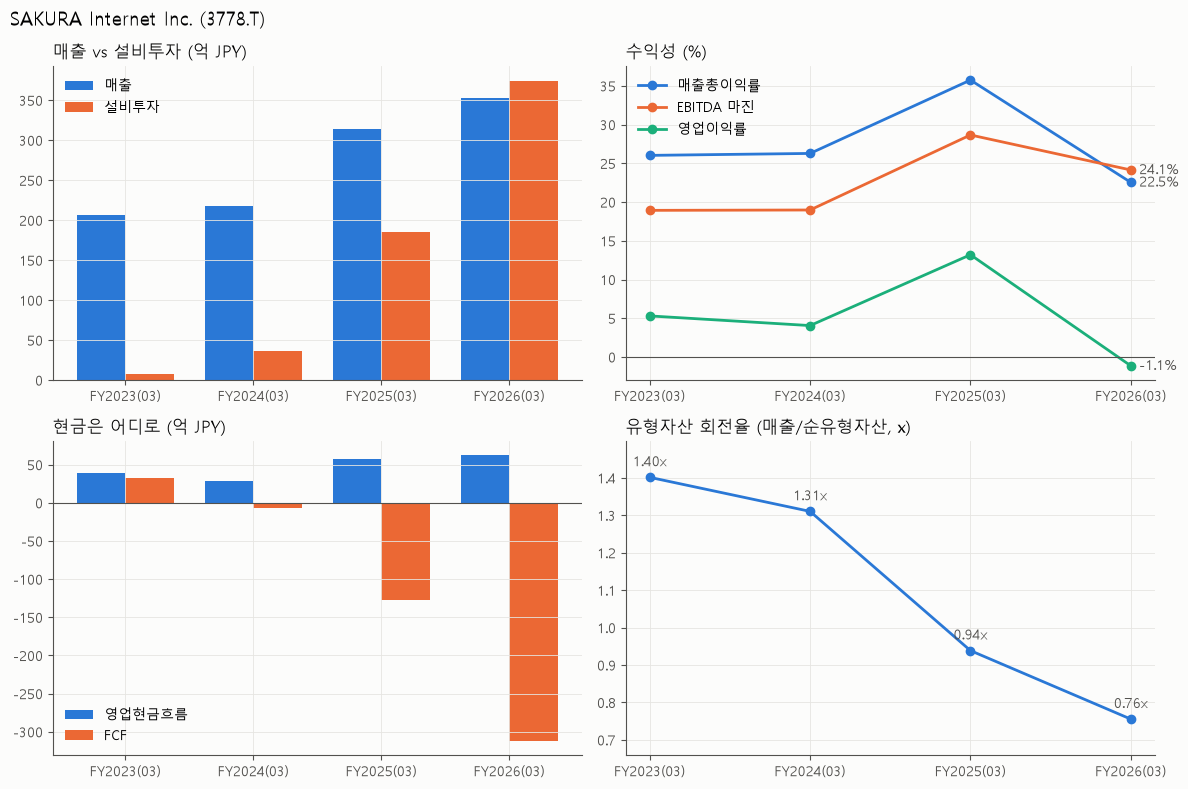

In [5]:
import numpy as np
x = np.arange(len(r.index)); labels = list(r.index)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

a = ax[0, 0]; w = 0.38
a.bar(x - w/2, items["revenue"] / 1e8, w, color=BLUE, label="매출")
a.bar(x + w/2, -items["capex"] / 1e8, w, color=ORANGE, label="설비투자")
a.set_title(f"매출 vs 설비투자 (억 {CUR})", loc="left"); a.legend(frameon=False)

a = ax[0, 1]
for col, c, name in (("GM", BLUE, "매출총이익률"), ("EBITDA_M", ORANGE, "EBITDA 마진"), ("OPM", AQUA, "영업이익률")):
    a.plot(x, r[col], color=c, lw=2, marker="o", ms=6, label=name)
    a.annotate(f"{r[col].iloc[-1]:.1f}%", (x[-1], r[col].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", color="#52514e")
a.axhline(0, color="#52514e", lw=0.8); a.set_title("수익성 (%)", loc="left"); a.legend(frameon=False)

a = ax[1, 0]
a.bar(x - w/2, items["cfo"] / 1e8, w, color=BLUE, label="영업현금흐름")
a.bar(x + w/2, items["fcf"] / 1e8, w, color=ORANGE, label="FCF")
a.axhline(0, color="#52514e", lw=0.8); a.set_title(f"현금은 어디로 (억 {CUR})", loc="left"); a.legend(frameon=False)

a = ax[1, 1]
a.plot(x, r["PPE_TURN"], color=BLUE, lw=2, marker="o", ms=6)
for xi, v in zip(x, r["PPE_TURN"]):
    a.annotate(f"{v:.2f}x", (xi, v), xytext=(0, 8), textcoords="offset points", ha="center", color="#52514e")
a.set_title("유형자산 회전율 (매출/순유형자산, x)", loc="left"); a.margins(y=0.15)

for a in ax.flat:
    a.set_xticks(x, labels)
fig.suptitle(f"{info.get('longName')} ({TICKER})", x=0.01, ha="left", fontsize=14)
fig.tight_layout(); plt.show()

## 4. 숫자가 던지는 질문

섹터 플레이북([playbooks/](../playbooks/))의 규칙으로 자동 생성한 질문이다. 기준을 바꾸려면 코드가 아니라 YAML을 고친다. **답이 아니라 질문**이다. 각 질문은 공시·실적발표에서 답을 찾아야 하고, 답을 찾으면 그게 투자 논거나 반대 논거의 재료가 된다.

- 🔴 red: 투자 논거가 성립하려면 반드시 답해야 하는 것
- 🟡 yellow: 원인을 설명할 수 있어야 하는 변화

In [6]:
qs = fin.questions(r, playbook=pb)
icon = {"red": "🔴", "yellow": "🟡"}
display(Markdown("\n".join(f"- {icon[q['level']]} `{q['evidence_id']}` {q['question']}" for q in qs) or "플래그 없음"))

- 🟡 `GM_FY2025` FY2025(03) 매출총이익률이 26.3%→35.8%로 +9.5%p 변했다. 가격(단가) 때문인가, 원가(전력·감가상각·외주) 때문인가, 매출 구성 변화 때문인가?
- 🟡 `OPM_FY2025` FY2025(03) 영업이익률 4.1%→13.2%. 매출총이익 변화와 판관비 중 어느 쪽이 컸나?
- 🟡 `SHARE_G_FY2025` FY2025(03) 발행주식수 +12.0%. 증자 자금은 어디에 썼고, 희석을 넘는 이익 증가가 있었나?
- 🔴 `PPE_TURN_FY2025` FY2025(03) 유형자산 회전율 1.31x→0.94x. 자산이 매출보다 훨씬 빨리 늘었다. 가동률은? 계약된 수요가 있는 투자인가?
- 🟡 `GM_FY2026` FY2026(03) 매출총이익률이 35.8%→22.5%로 -13.2%p 변했다. 가격(단가) 때문인가, 원가(전력·감가상각·외주) 때문인가, 매출 구성 변화 때문인가?
- 🟡 `OPM_FY2026` FY2026(03) 영업이익률 13.2%→-1.1%. 매출총이익 변화와 판관비 중 어느 쪽이 컸나?
- 🔴 `FCF_M_FY2026` FY2026(03) FCF 마진 -88.4%. 마이너스 FCF는 언제 끝나고, 그때까지 자금은 충분한가?
- 🟡 `DA_REV_FY2026` FY2026(03) 감가상각비/매출이 15.2%→21.9%로 올랐다. 새로 들인 설비(GPU)가 매출을 따라오기 전에 비용부터 반영되는 중인가? 내용연수 가정은 몇 년인가?
- 🔴 `PPE_TURN_FY2026` FY2026(03) 유형자산 회전율 0.94x→0.76x. 자산이 매출보다 훨씬 빨리 늘었다. 가동률은? 계약된 수요가 있는 투자인가?
- 🟡 `CAPEX_REV_FY2026` FY2026(03) 설비투자가 매출의 106.1%다. 투자 회수 기간과 자금 조달(차입·증자·보조금)은?

## 5. 비교: 같은 '인터넷 인프라'인데 무엇이 다른가

최근 회계연도 기준. 결산월이 다르면(12월 vs 3월) 같은 시점이 아니다. 비교 대상의 사업 구성이 다르다는 점(예: GMO는 결제·금융 사업 포함)을 감안해서 읽을 것.

In [7]:
peers = fin.peer_table(PEERS, refresh=REFRESH, metrics=pb["metrics"])
peers.T

,SAKURA INTERNET INC (3778.T),INTERNET INITIATIVE JAPAN INC (3774.T),GMO INTERNET GROUP INC (9449.T)
최근 회계연도,FY2026(03),FY2026(03),FY2025(12)
매출 성장률,12.38,9.02,2.19
매출총이익률,22.54,22.05,59.98
영업이익률,-1.14,10.09,20.72
EBITDA 마진,24.14,20.07,28.28
FCF 마진,-88.44,6.36,15.24
영업현금흐름/순이익,28.81,2.09,3.32
ROE,0.72,16.20,16.35
ROIC(세후 영업이익/투하자본),-0.80,13.12,6.03
순차입금/EBITDA,2.40,-0.09,-11.21


## 6. 숫자 → 이야기: 내 해석 쓰기

위 표·차트·질문을 보고 **내 말로** 아래 세 가지를 써 본다. 이 문장들이 02 노트북의 첫 번째 논거가 된다. 근거로 쓰는 지표는 `[GM_FY2026]`처럼 id를 붙인다.

1. **이 회사는 지금 어떤 국면인가?** (예: 수확기 / 투자기 / 구조조정기)
2. **시장은 무엇을 믿고 있고, 숫자 중 무엇이 그 믿음과 맞거나 어긋나나?**
3. **위 질문 중 내 논거를 무너뜨릴 수 있는 것은 무엇인가?**

> 여기에 직접 작성하세요.

In [8]:
# 02 노트북이 쓸 근거 파일 저장
ev = fin.evidence(r, CUR, metrics=pb["metrics"])
out = ROOT / "data" / "evidence"; out.mkdir(parents=True, exist_ok=True)
(out / f"{TICKER}.json").write_text(json.dumps({"ticker": TICKER, "company": info.get("longName"), "currency": CUR,
                                               "playbook": PLAYBOOK, "evidence": ev, "questions": qs}, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"근거 {len(ev)}개, 질문 {len(qs)}개 저장 -> data/evidence/{TICKER}.json")

근거 64개, 질문 10개 저장 -> data/evidence/3778.T.json
